# Session 16: Introduction to Deep Learning and Image Processing

**Learning goals:**

- Distinguish features, targets and model parameters, and explain training and inference.
- Explain how deeper networks build hierarchical representations.
- Relate algorithms, large datasets and computing hardware to the success of deep learning.
- Identify key contributors to deep learning and image recognition.
- Explain convolution, shared filters, stride, padding, pooling, fully connected layers and softmax.
- Compare LeNet-5, AlexNet, VGGNet and ResNet, including small filters and residual connections.
- Apply image filters and visualise MNIST digit images.
- Train a scikit-learn MLP and a PyTorch CNN on the same split, compare held-out predictions and measure CPU/GPU inference time.

**Prerequisites:**

- Supervised learning, classification, train/test splits and model evaluation.
- Basic Python functions, classes, loops and NumPy arrays.
- Python with Pillow, Matplotlib, NumPy, pandas, scikit-learn and PyTorch installed in the notebook environment.
- A GPU is optional; all practical examples can run on CPU.



## Outline

1. From machine learning to deep learning
2. Key scientists and contributors
3. CNN building blocks and image filtering
4. Popular CNN architectures
5. Why networks became deeper rather than only wider
6. Image classification: separate MLP and CNN workflows, evaluation and comparison

Work through Sections 1–3, including the image-filtering example, before continuing to architectures, model training and evaluation in Sections 4–6.


## 1. From Machine Learning to Deep Learning


### 1.1 Machine learning: learn from history

Machine learning (ML) builds a useful relationship from historical examples. In **supervised learning**, each example pairs **features** (the input measurements or attributes) with a known **target** (the value or class to predict). For digit recognition, the features are pixel values and the target is the digit label.

Instead of manually writing every rule, practitioners select a **method/algorithm** that learns the relationship between features and targets. Training uses the historical feature–target pairs to adjust **model parameters**, such as weights and biases. These parameters represent the learnt relationship between features and targets; they are different from the features and targets in the dataset.

During **inference**, the trained model receives features for a new case and produces a **predicted target**. The known target for that new case is not supplied as an input to the model.

![Historical features and known targets train model parameters that represent their relationship. The trained model maps new features to a predicted target.](assets/ml-learning-from-history.svg){fig-alt="Historical feature–target pairs pass through a learning algorithm to produce parameters representing the relationship between features and targets. The trained model maps new features to a predicted target." style="width: 100%; height: auto;"}


### 1.2 Why add more layers?

A single layer can capture a limited transformation. Multiple layers can build a hierarchy: early layers detect simple patterns, middle layers combine them, and later layers form task-specific concepts. The CNN below illustrates the progression from edges and textures to outlines, shapes and a final class prediction.

![A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog](assets/cnn-dog-feature-extraction.png){fig-alt="A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog" style="width: 100%; height: auto;"}

- **Early layers:** local edges and colour changes
- **Middle layers:** textures, contours and reusable parts
- **Later layers:** whole-object evidence and a task output


### 1.3 Why deep learning became successful

![Algorithms update network weights from errors, big data supplies many input-output examples, and a GPU processes matrix operations in parallel](assets/why-deep-learning.svg){fig-alt="Three panels show error-driven weight updates, many historical input-output pairs, and parallel GPU matrix processing" style="width: 100%; height: auto;"}

- **Algorithms:** backpropagation, improved activation functions, optimisation methods and model architectures made deeper networks easier to train.
- **Big data:** more historical examples exposed useful patterns and supported models with greater capacity.
- **Higher-performance computing:** GPUs, specialised accelerators and distributed training made large-scale calculations practical.


## 2 - Key Scientists and Contributors

Modern image recognition is the result of many people and many research groups. The names below are useful starting points for students because each one connects to a different part of the story.

| Scientist | Why they matter for deep learning and image recognition |
|---|---|
| [Geoffrey Hinton](https://en.wikipedia.org/wiki/Geoffrey_Hinton) | Helped revive neural networks, popularised representation learning, co-authored the AlexNet paper, and contributed to backpropagation, Boltzmann machines, and knowledge distillation. |
| [Yann LeCun](https://en.wikipedia.org/wiki/Yann_LeCun) | Developed LeNet-style CNNs for handwritten digit recognition and made convolutional networks central to computer vision. |
| [Yoshua Bengio](https://en.wikipedia.org/wiki/Yoshua_Bengio) | Helped develop deep learning theory and representation learning, especially for training deep neural networks. |
| [Fei-Fei Li](https://en.wikipedia.org/wiki/Fei-Fei_Li) | Led work on ImageNet, a large labelled image dataset that helped make large-scale visual recognition measurable and competitive. |
| [Kunihiko Fukushima](https://en.wikipedia.org/wiki/Kunihiko_Fukushima) | Proposed the Neocognitron, an early biologically inspired model with ideas similar to later convolution and pooling. |
| [Jürgen Schmidhuber](https://en.wikipedia.org/wiki/J%C3%BCrgen_Schmidhuber) | Contributed to deep learning and recurrent networks, and his group worked on early GPU-accelerated neural networks. |
| [Kaiming He](https://en.wikipedia.org/wiki/Kaiming_He) | Co-authored ResNet and He initialisation, both important for training very deep networks. |

A useful way to read this history is not as one inventor story, but as a stack of ideas: datasets, compute, architectures, optimisation methods, and open-source tools all improved together.


## 3 - CNN Building Blocks

[Video: CNNs](https://www.youtube.com/watch?v=ip2HYPC_T9Q)


{{< video https://www.youtube.com/embed/ip2HYPC_T9Q?hl=en title="CNNs" aria-label="Video explaining convolutional neural networks" aspect-ratio="16x9" >}}


A CNN for image classification can be understood as four main parts. The early layers extract useful visual features; the final layers turn those features into a class prediction.

| Component | Role |
|---|---|
| **Convolutional layer** | Uses learnable filters to extract local features such as edges, corners, textures, and shapes. |
| **Pooling layer** | Shrinks feature maps while keeping the strongest or average signal in each local region. |
| **Fully connected layer** | Combines extracted features to produce class scores. |
| **Softmax** | Converts class scores into probabilities that sum to 1. |


### 3.1 CNN Network Structure

The diagram below shows a typical CNN flow: image input, repeated convolution and pooling, then fully connected layers and a final prediction.

![Typical CNN architecture](assets/typical-cnn-architecture.png)

Interactive 3D demo: [Adam Harley - CNN 3D Visualisation](https://adamharley.com/nn_vis/cnn/3d.html). This visualisation shows how feature maps change as an image moves through a CNN.

Reference: inspired by [Pinecone - Visual Guide to Applied Convolution Neural Networks](https://www.pinecone.io/learn/series/image-search/cnn/). Images in this notebook are stored locally so they display offline.


### 3.2 Convolutional Layer: Filters Extract Features

A convolutional layer uses small filters to scan an image. Different filters respond to different visual patterns. For example, one filter may respond strongly to vertical edges, another to horizontal edges, and another to sharp outlines.

The animation below shows how a filter produces a feature map: the filter moves over the image, calculates one local response at a time, and builds a new representation for the next layer.

![Convolution filter producing a feature map](assets/convolution-filter-feature-map.gif)


### 3.3 Convolutional Computing

At each image position, the filter and the image patch are multiplied element by element. The products are then added together. That one number becomes one value in the output feature map.

![Convolution element-wise multiplication](assets/convolution-elementwise.png)

After this visual explanation, the next code cell applies several filters to the dog image to show how different filters highlight different features.


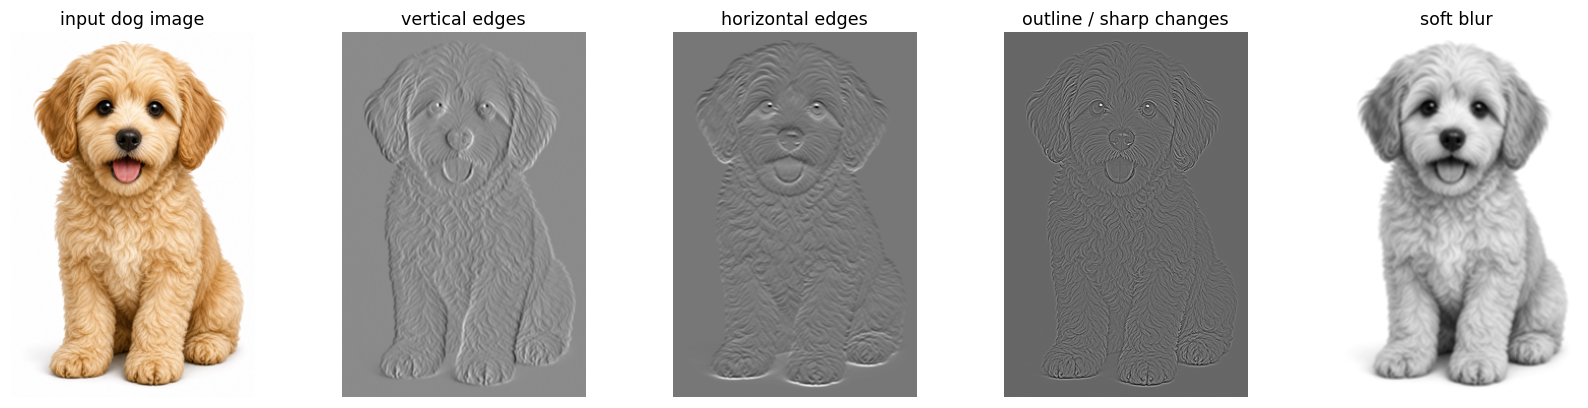

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DOG_IMAGE = "assets/dog_input.png"

# Load the image as RGB. Even though the filters below use greyscale, keeping the
# RGB version lets us display the original image beside the feature maps.
dog_rgb = Image.open(DOG_IMAGE).convert("RGB")

# Shrink the image so the nested loops below run quickly in a classroom notebook.
dog_rgb.thumbnail((360, 360))

# Convert image pixels from integers in [0, 255] to floats in [0, 1].
dog_rgb_array = np.asarray(dog_rgb, dtype=np.float32) / 255.0

# Convert RGB to greyscale using standard luminance weights.
# This gives one intensity value per pixel, which is easier for 2D filters.
dog_gray = (
    0.299 * dog_rgb_array[:, :, 0]
    + 0.587 * dog_rgb_array[:, :, 1]
    + 0.114 * dog_rgb_array[:, :, 2]
)

# Each small matrix below is a filter/kernel. Positive and negative values make
# the filter respond strongly to different patterns, such as edges or outlines.
filters = {
    "vertical edges": np.array(
        [
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1],
        ],
        dtype=np.float32,
    ),
    "horizontal edges": np.array(
        [
            [-1, -2, -1],
            [0, 0, 0],
            [1, 2, 1],
        ],
        dtype=np.float32,
    ),
    "outline / sharp changes": np.array(
        [
            [0, -1, 0],
            [-1, 4, -1],
            [0, -1, 0],
        ],
        dtype=np.float32,
    ),
    "soft blur": np.array(
        [
            [1, 1, 1],
            [1, 1, 1],
            [1, 1, 1],
        ],
        dtype=np.float32,
    ) / 9.0,
}


def apply_filter(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply a small 2D filter using edge padding."""
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    # Padding lets the filter still be centred on border pixels.
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="edge")
    output = np.zeros_like(image, dtype=np.float32)

    # Slide the filter over every pixel location.
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            # Extract the local image patch covered by the filter.
            patch = padded[row : row + kh, col : col + kw]

            # Element-wise multiply the patch and filter, then sum to one value.
            output[row, col] = np.sum(patch * kernel)

    return output


# Apply every filter and plot the resulting feature maps side by side.
feature_maps = {name: apply_filter(dog_gray, kernel) for name, kernel in filters.items()}

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(dog_rgb_array)
axes[0].set_title("input dog image")
axes[0].axis("off")

for ax, (name, feature_map) in zip(axes[1:], feature_maps.items()):
    ax.imshow(feature_map, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()  # Display the original image and the filtered feature maps.


### 3.4 Stride and Padding

**Stride** controls how far the filter moves each step. A stride of `1` checks neighbouring positions; a stride of `2` skips one position each time and produces a smaller feature map.

![Convolution stride](assets/convolution-stride.gif)

**Padding** adds extra pixels around the border before convolution. Padding helps the filter process edge pixels and can keep the output height and width closer to the input size.

![Convolution padding](assets/convolution-padding.png)


### 3.5 Pooling Layer

Pooling compresses a small region into one value. In **max pooling**, the largest value is kept. In **average pooling**, the mean value is kept.

![Average vs max pooling](assets/pooling-average-vs-max.png)

A small max-pooling example with a 2 by 2 window:

```text
Input region       Max pooling output

[1  3]
[2  4]       ->    4
```

A larger example with four non-overlapping 2 by 2 windows:

```text
Input feature map          Max-pooled feature map

[1  3  2  0]               [4  5]
[2  4  1  5]       ->      [8  7]
[0  1  7  3]
[6  8  2  4]
```


### 3.6 Fully Connected Layer and Softmax

After several convolution and pooling steps, the image has become a compact set of feature maps. These feature maps are flattened, or globally pooled, and then passed into a **fully connected classifier**.

A fully connected classifier is essentially an MLP-style classifier head: each neuron receives input from all values in the previous layer. It combines the extracted CNN features into class scores, also called **logits**.

![Fully connected layer](assets/fully-connected-layer.png)

Softmax is usually applied after the final fully connected layer for multi-class classification. It converts logits into probabilities that sum to 1, so the largest probability becomes the predicted class.

![Softmax output](assets/softmax-output.png)

A useful summary is:

```text
Convolution + pooling layers
-> extracted feature maps
-> flatten or global average pooling
-> fully connected classifier / MLP head
-> logits
-> softmax probabilities
-> predicted class
```

In PyTorch training code, the model often returns logits directly. `nn.CrossEntropyLoss()` then handles the softmax-like calculation internally, so we usually do not add an explicit `Softmax` layer before the loss.



## 4 - Popular Architectures

CNN image recognition developed rapidly after **AlexNet** won ILSVRC 2012 and greatly improved the state-of-the-art accuracy. Later architectures mainly improved depth, training stability, and computational efficiency.

![Evolution of CNN architectures](assets/cnn-architecture-evolution.png)

| Architecture | Year | Typical depth | Approx. parameters | Key contributions |
|---|---:|---:|---:|---|
| **LeNet-5** | 1998 | 7 layers | ~60 thousand | Convolution, pooling, and fully connected classification. |
| **AlexNet** | 2012 | 8 layers | ~60 million | ReLU, dropout, GPU training, and ImageNet-scale training. |
| **VGGNet** | 2014 | 16 or 19 layers | ~138-143 million | Repeated small 3 by 3 filters to build deeper CNNs. |
| **ResNet** | 2015 | 18 to 152+ layers | ~11.7-60.2 million | Residual networks for training very deep CNNs. |


### 4.1 LeNet-5

LeNet-5 is an early CNN for handwritten digit recognition. It alternates convolution and pooling, then uses fully connected layers for classification.

![LeNet-5 architecture](assets/lenet5-architecture.png)


### 4.2 AlexNet

AlexNet won ILSVRC 2012 and made large-scale CNN image classification a mainstream approach.

![AlexNet architecture](assets/alexnet-architecture.png)

Key points:

- **ReLU** uses `ReLU(x) = max(0, x)`. It is simple, fast, and keeps stronger gradients for positive values.
- **Dropout** randomly sets some activations to zero during training, reducing overfitting in fully connected layers.
- **GPU training** made the large CNN practical to train on ImageNet.

Activation functions add non-linearity so that neural networks can learn complex patterns. Earlier networks often used sigmoid or tanh, but these functions can saturate and make gradients small.

![Activation functions](assets/activation-functions.png)

The training curve below illustrates why ReLU became popular: it can reduce training error faster than tanh in deep CNNs.

![ReLU training advantage](assets/relu-training-advantage.png)


### 4.3 VGGNet

VGGNet uses a simple deep structure based on repeated **3 by 3 convolutions**.

![VGGNet architecture](assets/vggnet-architecture.png)

Key point: several small convolutions can replace one large convolution with fewer parameters and fewer multiply-add operations.

Ignoring bias terms, for a convolution with kernel size `k x k`, input channels `C_in`, output channels `C_out`, and output feature map size `H x W`:

$$
\text{parameters} = k^2 C_{in} C_{out}
$$

$$
\text{multiply-adds} \approx H W k^2 C_{in} C_{out}
$$

If `C_in = C_out = C`, one `5 x 5` convolution has:

$$
25C^2 \text{ parameters}, \quad HW \cdot 25C^2 \text{ multiply-adds}
$$

Two `3 x 3` convolutions have a similar receptive field but only:

$$
2 \times 9C^2 = 18C^2 \text{ parameters}, \quad HW \cdot 18C^2 \text{ multiply-adds}
$$

So the small-filter design reduces cost and adds an extra ReLU, giving the network more feature transformations.


### 4.4 ResNet

ResNet's key contribution is the **residual network**, which made very deep CNNs practical to train.

![ResNet architecture](assets/resnet-architecture.png)

As CNNs become deeper, gradients can become very small when they are backpropagated through many layers. This **vanishing gradient** problem makes early layers learn slowly, and adding more layers can even make training accuracy worse.

A residual block adds a shortcut connection:

$$
\mathbf{y} = F(\mathbf{x}) + \mathbf{x}
$$

The shortcut gives gradients a more direct path back through the network. Instead of learning a full mapping from scratch, the block only needs to learn the correction `F(x)`. If extra layers are not useful, the block can learn a near-zero correction and pass the input forward.

**Batch Normalisation** normalises activations during training, then learns a scale and shift. It stabilises training and helps deep networks use larger learning rates.


## 5 - Why Did Networks Become Deeper Rather Than Only Wider?

1. **From local to global image understanding**: shallow convolutional layers have small receptive fields and learn local features such as edges, corners, and textures. Deeper layers combine features from earlier layers, so the representation becomes more abstract and specific: early layers may detect animal-like patterns, later layers may recognise a dog, and still deeper layers may separate breeds such as Husky or Staffordshire Bull Terrier.

2. **Fewer weights by trading width for depth**: multiple small convolutions can replace one large convolution. For example, two `3 x 3` convolutions can cover a similar area to one `5 x 5` convolution, but use fewer weights and add more non-linear feature transformations.

3. **Trainable deep networks**: residual networks use shortcut connections to reduce vanishing-gradient problems, making much deeper CNNs practical to train.

4. **GPU acceleration**: convolution is highly parallel, so GPUs make large CNN training much faster than CPUs.


## 6 - Image Classification with scikit-learn and a CNN

This section demonstrates four practical steps:

1. load and visualise MNIST;
2. train and evaluate with an MLP;
3. train and evaluate with a CNN;
4. compare the results.

[Download the practice notebook](<Session16.1 MNIST Image Classification Practice.ipynb>){download="Session16.1 MNIST Image Classification Practice.ipynb" data-noresolveinput="true"}

The practice notebook contains the code and short explanations from this section. Save it in the course folder beside `sample_data/`, and use Python with pandas, NumPy, Matplotlib, scikit-learn and PyTorch installed.

Load and split the data once in Section 6.1, then use those shared arrays for both classifiers. Run both models before comparing their results.


### 6.1 Load and Visualise MNIST

The CSV has no header: column 0 contains the digit target and the remaining 784 columns contain the 28 × 28 greyscale pixels. Divide pixels by 255 to scale them to [0, 1]. Create one stratified 80/20 split for both models, and keep the test data out of training.


Training images: 4,800; test images: 1,200
Flattened training input shape: (4800, 784)


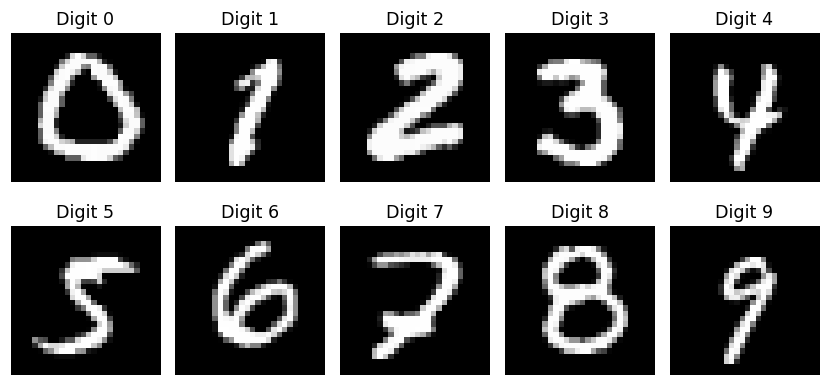

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

MNIST_CSV = "sample_data/mnist_train_small.csv"
IMAGE_SIDE = 28
RANDOM_STATE = 42
TEST_FRACTION = 0.2

# Load the label column and the 784 pixel columns without a header row.
mnist_data = pd.read_csv(MNIST_CSV, header=None)
digit_labels = mnist_data.iloc[:, 0].to_numpy(dtype="int64")
digit_pixels = mnist_data.iloc[:, 1:].to_numpy(dtype="float32") / 255.0

# Split once so both classifiers use the same training and test images.
train_rows, test_rows = train_test_split(
    np.arange(len(digit_labels)), test_size=TEST_FRACTION,
    random_state=RANDOM_STATE, stratify=digit_labels,
)
train_pixels, test_pixels = digit_pixels[train_rows], digit_pixels[test_rows]
train_labels, test_labels = digit_labels[train_rows], digit_labels[test_rows]
print(f"Training images: {len(train_rows):,}; test images: {len(test_rows):,}")
print(f"Flattened training input shape: {train_pixels.shape}")

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for digit, ax in enumerate(axes.ravel()):
    # Reshape one training example per digit for display, without changing model inputs.
    image = train_pixels[train_labels == digit][0].reshape(IMAGE_SIDE, IMAGE_SIDE)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 6.2 Train and Evaluate with an MLP

An MLP treats each image as a vector of 784 pixel features. Use scikit-learn's [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) with the shared `train_pixels`, `test_pixels`, `train_labels` and `test_labels` arrays from Section 6.1.


#### 6.2.1 Train the MLP

Use one hidden layer with 64 ReLU units and the Adam optimiser. One call to `partial_fit` makes one training pass (epoch) over the supplied data, allowing us to record loss after each of five epochs. The first call receives all possible digit classes. Training continues from the existing weights on later calls.

`alpha=0.0` disables the MLP's L2 penalty for this example. The test set is not used to select weights or the epoch count.

In [3]:
from sklearn.neural_network import MLPClassifier
import time

MLP_HIDDEN_UNITS = 64
MLP_BATCH_SIZE = 64
MLP_LEARNING_RATE = 0.001
MLP_EPOCHS = 5
MLP_CLASSES = np.arange(10)

mlp_model = MLPClassifier(
    hidden_layer_sizes=(MLP_HIDDEN_UNITS,),  # One hidden layer with 64 neurons.
    activation="relu", solver="adam", alpha=0.0,
    batch_size=MLP_BATCH_SIZE, learning_rate_init=MLP_LEARNING_RATE,
    shuffle=True, random_state=RANDOM_STATE,
)
mlp_loss_history = []
mlp_start = time.perf_counter()
for epoch in range(MLP_EPOCHS):
    # Supply the complete class list on the first incremental training call.
    if epoch == 0:
        mlp_model.partial_fit(train_pixels, train_labels, classes=MLP_CLASSES)
    else:
        mlp_model.partial_fit(train_pixels, train_labels)
    mlp_loss_history.append(mlp_model.loss_)
    print(f"MLP epoch {epoch + 1}/{MLP_EPOCHS}: loss={mlp_model.loss_:.4f}")
mlp_training_seconds = time.perf_counter() - mlp_start


MLP epoch 1/5: loss=1.1129
MLP epoch 2/5: loss=0.4580
MLP epoch 3/5: loss=0.3539
MLP epoch 4/5: loss=0.2996
MLP epoch 5/5: loss=0.2624


#### 6.2.2 Evaluate the MLP

Use `predict` on the held-out images. Accuracy summarises the fraction classified correctly; macro F1 gives each digit equal weight. The classification report and confusion matrix reveal which digits are confused. Compare training and test accuracy to look for a generalisation gap.

MLP training accuracy: 0.941
MLP test accuracy: 0.914; macro F1: 0.914
              precision    recall  f1-score   support

           0      0.944     0.975     0.959       120
           1      0.982     0.925     0.953       120
           2      0.940     0.908     0.924       120
           3      0.887     0.850     0.868       120
           4      0.900     0.900     0.900       120
           5      0.872     0.850     0.861       120
           6      0.948     0.917     0.932       120
           7      0.941     0.933     0.937       120
           8      0.848     0.933     0.889       120
           9      0.891     0.950     0.919       120

    accuracy                          0.914      1200
   macro avg      0.915     0.914     0.914      1200
weighted avg      0.915     0.914     0.914      1200



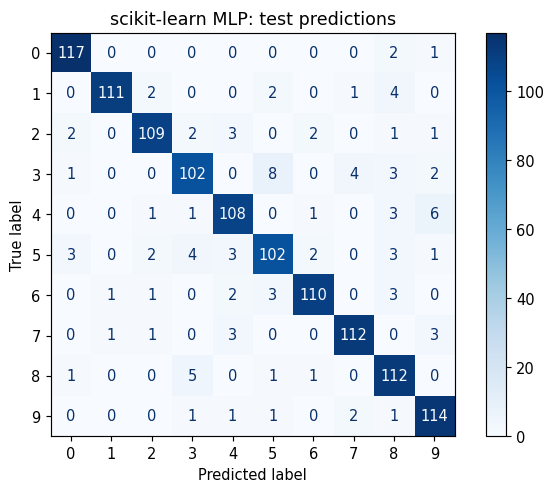

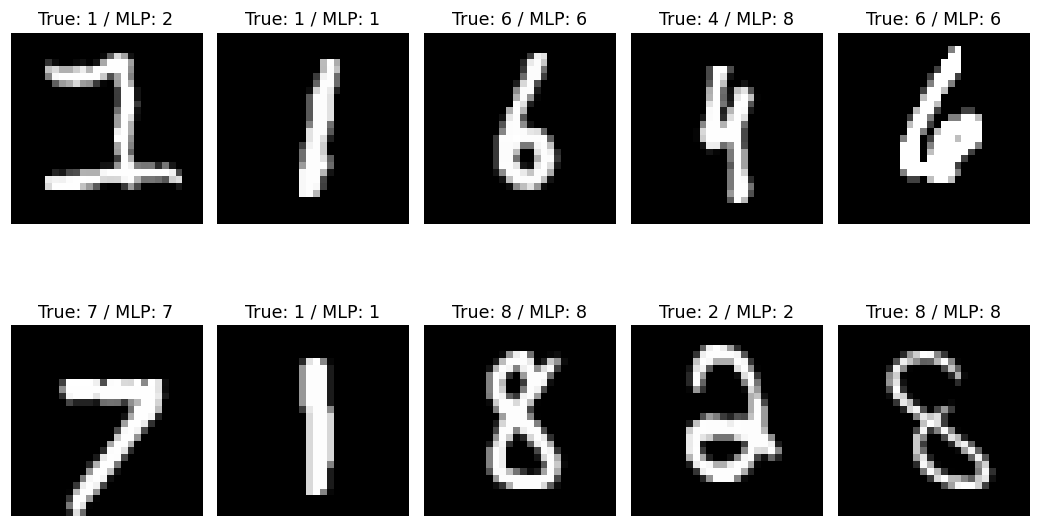

In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

mlp_predictions = mlp_model.predict(test_pixels)  # Predict labels without updating weights.
mlp_train_accuracy = mlp_model.score(train_pixels, train_labels)
mlp_test_accuracy = accuracy_score(test_labels, mlp_predictions)
mlp_macro_f1 = f1_score(test_labels, mlp_predictions, average="macro")
print(f"MLP training accuracy: {mlp_train_accuracy:.3f}")
print(f"MLP test accuracy: {mlp_test_accuracy:.3f}; macro F1: {mlp_macro_f1:.3f}")
print(classification_report(test_labels, mlp_predictions, digits=3, zero_division=0))

# Rows show true classes; columns show predicted classes.
ConfusionMatrixDisplay.from_predictions(test_labels, mlp_predictions, cmap="Blues")
plt.title("scikit-learn MLP: test predictions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(test_pixels[index].reshape(IMAGE_SIDE, IMAGE_SIDE), cmap="gray")
    ax.set_title(f"True: {test_labels[index]} / MLP: {mlp_predictions[index]}")
    ax.axis("off")
plt.tight_layout(h_pad=3.0)  # Leave room between rows for prediction labels.
plt.show()


### 6.3 Train and Evaluate with a CNN

Use the same shared training and test arrays from Section 6.1. The CNN restores the spatial layout of each image instead of using the flattened representation as its model input.

#### 6.3.1 Prepare Image Batches

Reshape the shared pixel arrays into tensors shaped `(batch, 1, 28, 28)` and create data loaders. Shuffle only the training batches. The fixed seed helps reproduce initial weights and batch order; accelerator results can still vary.


In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

CNN_BATCH_SIZE = 64
NUM_CLASSES = 10
HIDDEN_UNITS = 64
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(RANDOM_STATE)  # Seed CNN initial weights.

# Restore the image dimensions and add a single greyscale channel.
cnn_train_images = torch.from_numpy(train_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
cnn_test_images = torch.from_numpy(test_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
cnn_train_dataset = TensorDataset(cnn_train_images, torch.from_numpy(train_labels))
cnn_test_dataset = TensorDataset(cnn_test_images, torch.from_numpy(test_labels))
cnn_shuffle_generator = torch.Generator().manual_seed(RANDOM_STATE)
cnn_train_loader = DataLoader(
    cnn_train_dataset, batch_size=CNN_BATCH_SIZE, shuffle=True,
    generator=cnn_shuffle_generator,  # Reproduce the training shuffle order.
)
cnn_test_loader = DataLoader(cnn_test_dataset, batch_size=CNN_BATCH_SIZE, shuffle=False)
print(f"Training images: {len(train_labels):,}; test images: {len(test_labels):,}")
print(f"CNN input shape: {tuple(cnn_train_images.shape)}; device: {DEVICE}")


Training images: 4,800; test images: 1,200
CNN input shape: (4800, 1, 28, 28); device: cpu


#### 6.3.2 Define and train the CNN

Two convolution–ReLU–pooling blocks extract spatial features, followed by a 64-unit classifier. The final layer returns raw logits; `CrossEntropyLoss` applies the appropriate log-softmax calculation internally.

For every training batch, clear gradients, calculate the loss, backpropagate and update the weights. Train for five epochs with Adam, batch size 64 and learning rate 0.001. These match the MLP's broad settings, although the libraries use different initialisation and optimisation details.

In [6]:
class SimpleCNN(nn.Module):
    """Extract local image features before fully connected classification."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  # Preserve 28 × 28 spatial size.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 28 × 28 to 14 × 14.
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # Learn 32 feature maps.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 14 × 14 to 7 × 7.
        )
        pooled_side = IMAGE_SIDE // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),  # Join the 32 feature maps into one vector per image.
            nn.Linear(32 * pooled_side * pooled_side, HIDDEN_UNITS),
            nn.ReLU(),
            nn.Linear(HIDDEN_UNITS, NUM_CLASSES),  # Return one logit for each digit.
        )

    def forward(self, images):
        return self.classifier(self.features(images))


In [7]:
import time

CNN_EPOCHS = 5
CNN_LEARNING_RATE = 0.001
simple_cnn = SimpleCNN().to(DEVICE)  # Move the new model to the selected device.
cnn_loss_function = nn.CrossEntropyLoss()
cnn_optimiser = torch.optim.Adam(simple_cnn.parameters(), lr=CNN_LEARNING_RATE)
cnn_loss_history = []


def synchronise(device):
    """Wait for accelerator work before recording elapsed time."""
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


synchronise(DEVICE)
cnn_start = time.perf_counter()
for epoch in range(CNN_EPOCHS):
    simple_cnn.train()  # Enable training behaviour for this epoch.
    cnn_total_loss = 0.0
    for images, labels in cnn_train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        cnn_optimiser.zero_grad()  # Remove the previous batch's gradients.
        logits = simple_cnn(images)
        loss = cnn_loss_function(logits, labels)
        loss.backward()  # Calculate the parameter gradients.
        cnn_optimiser.step()  # Update model weights using Adam.
        cnn_total_loss += loss.item() * len(labels)
    cnn_epoch_loss = cnn_total_loss / len(cnn_train_dataset)
    cnn_loss_history.append(cnn_epoch_loss)
    print(f"CNN epoch {epoch + 1}/{CNN_EPOCHS}: loss={cnn_epoch_loss:.4f}")
synchronise(DEVICE)
cnn_training_seconds = time.perf_counter() - cnn_start


CNN epoch 1/5: loss=1.2329
CNN epoch 2/5: loss=0.3998
CNN epoch 3/5: loss=0.2813
CNN epoch 4/5: loss=0.2167
CNN epoch 5/5: loss=0.1797


#### 6.3.3 Evaluate the CNN

Switch to evaluation mode and disable gradient tracking. Collect predictions in test-loader order, then calculate the same metrics used for the MLP. The training accuracy below is measured after training has finished.

CNN training accuracy: 0.956
CNN test accuracy: 0.934; macro F1: 0.934
              precision    recall  f1-score   support

           0      0.952     0.983     0.967       120
           1      0.974     0.950     0.962       120
           2      0.966     0.942     0.954       120
           3      0.881     0.925     0.902       120
           4      0.972     0.883     0.926       120
           5      0.919     0.942     0.930       120
           6      0.950     0.942     0.946       120
           7      0.862     0.992     0.922       120
           8      0.940     0.908     0.924       120
           9      0.946     0.875     0.909       120

    accuracy                          0.934      1200
   macro avg      0.936     0.934     0.934      1200
weighted avg      0.936     0.934     0.934      1200



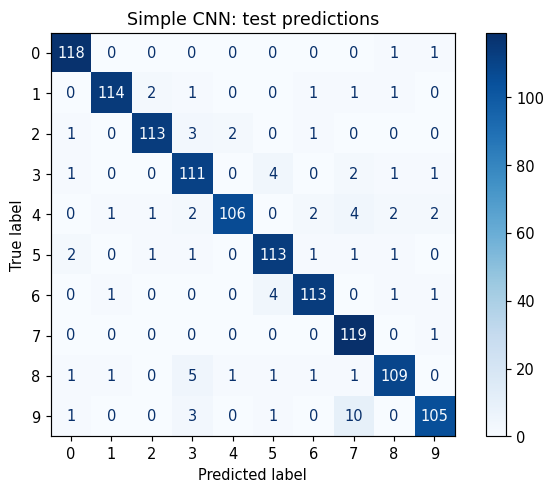

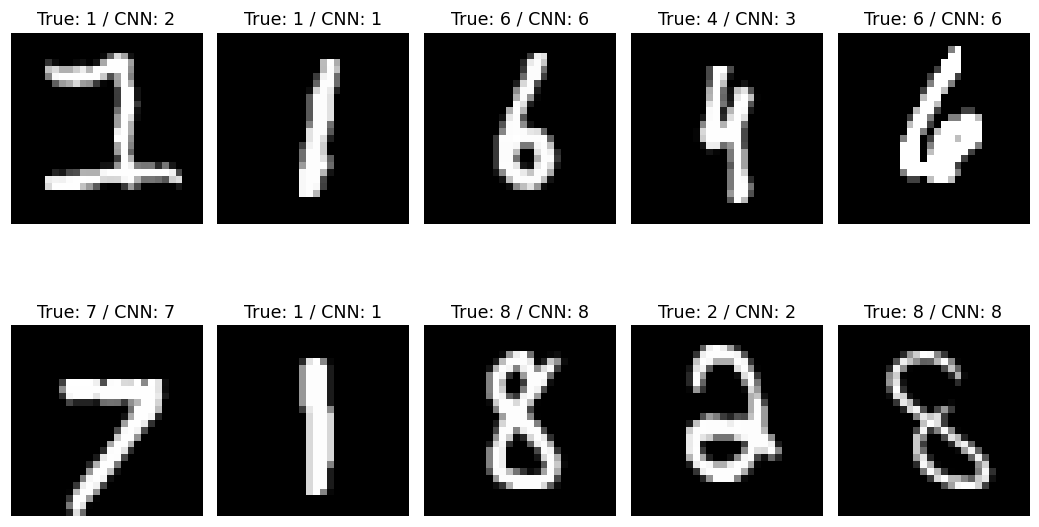

In [8]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay


def cnn_predict(loader):
    """Predict digit labels in loader order without changing the model weights."""
    simple_cnn.eval()
    batches = []
    with torch.no_grad():  # Evaluation does not need parameter gradients.
        for images, _ in loader:
            logits = simple_cnn(images.to(DEVICE))
            batches.append(logits.argmax(dim=1).cpu())
    return torch.cat(batches).numpy()


cnn_predictions = cnn_predict(cnn_test_loader)
# Preserve row order when measuring training accuracy after the final epoch.
cnn_train_eval_loader = DataLoader(cnn_train_dataset, batch_size=CNN_BATCH_SIZE, shuffle=False)
cnn_train_predictions = cnn_predict(cnn_train_eval_loader)
cnn_train_accuracy = accuracy_score(train_labels, cnn_train_predictions)
cnn_test_accuracy = accuracy_score(test_labels, cnn_predictions)
cnn_macro_f1 = f1_score(test_labels, cnn_predictions, average="macro")
print(f"CNN training accuracy: {cnn_train_accuracy:.3f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.3f}; macro F1: {cnn_macro_f1:.3f}")
print(classification_report(test_labels, cnn_predictions, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test_labels, cnn_predictions, cmap="Blues")
plt.title("Simple CNN: test predictions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(cnn_test_images[index, 0].numpy(), cmap="gray")
    ax.set_title(f"True: {test_labels[index]} / CNN: {cnn_predictions[index]}")
    ax.axis("off")
plt.tight_layout(h_pad=3.0)
plt.show()


#### 6.3.4 CPU and GPU Inference Time

Use the trained CNN and a fixed batch of held-out images to time forward passes. Warm-up runs reduce initial setup effects, and synchronisation waits for GPU work to finish. Timing excludes model/data transfer and training. A small model or batch may not benefit from a GPU; a CPU-only environment reports CPU results only.

In [9]:
def time_inference(model, batch, device, repeats):
    """Measure mean forward-pass time after moving the model and data."""
    model = model.to(device)
    batch = batch.to(device)
    model.eval()
    with torch.no_grad():
        for _ in range(3):  # Warm up kernels before starting the timer.
            model(batch)
        synchronise(device)
        start = time.perf_counter()
        for _ in range(repeats):
            model(batch)
        synchronise(device)
    return (time.perf_counter() - start) / repeats


TIMING_BATCH_SIZE = 16
TIMING_REPEATS = 5
cnn_timing_batch = cnn_test_images[:TIMING_BATCH_SIZE]
cnn_devices = ["cpu"]
if torch.cuda.is_available():
    cnn_devices.append("cuda")
elif torch.backends.mps.is_available():
    cnn_devices.append("mps")
cnn_timing_rows = []
for device in cnn_devices:
    seconds = time_inference(simple_cnn, cnn_timing_batch, device, TIMING_REPEATS)
    cnn_timing_rows.append({"device": device, "mean_forward_seconds": seconds})
simple_cnn = simple_cnn.to(DEVICE)  # Restore the model's training device.
pd.DataFrame(cnn_timing_rows)


,device,mean_forward_seconds
0,cpu,0.00106


### 6.4 Compare the Results

Run both classifiers before this subsection. They use the same shared split from Section 6.1. Compare test accuracy, macro F1, trainable parameters and training time.

| Feature | scikit-learn MLP | Simple CNN |
|---|---|---|
| Input | 784 flattened pixel values | One 28 × 28 greyscale channel |
| Architecture | 784 → 64 → 10 | Two convolution blocks → 64 → 10 |
| Feature learning | Dense connections between pixel positions | Local shared filters and pooling |
| Trainable parameters | 50,890 | 105,866 |
| Training | scikit-learn `MLPClassifier.partial_fit` | Explicit PyTorch training loop |

Both models use the same 80/20 split, pixel scaling, batch size, learning rate and five epochs. Their architectures, capacities, initialisation and implementation details differ, so this comparison does not isolate convolution as the only cause of any difference. The MLP runs on CPU; the CNN uses the device printed in its workflow. Training times describe this run and are not a hardware benchmark.

In [10]:
# Count weights and biases for each trained model.
mlp_parameter_count = sum(weights.size for weights in mlp_model.coefs_) + sum(
    biases.size for biases in mlp_model.intercepts_
)
cnn_parameter_count = sum(p.numel() for p in simple_cnn.parameters() if p.requires_grad)
comparison_df = pd.DataFrame([
    {"model": "scikit-learn MLP", "training_device": "cpu",
     "train_accuracy": mlp_train_accuracy, "test_accuracy": mlp_test_accuracy,
     "macro_f1": mlp_macro_f1, "parameters": mlp_parameter_count,
     "training_seconds": mlp_training_seconds},
    {"model": "Simple CNN", "training_device": DEVICE,
     "train_accuracy": cnn_train_accuracy, "test_accuracy": cnn_test_accuracy,
     "macro_f1": cnn_macro_f1, "parameters": cnn_parameter_count,
     "training_seconds": cnn_training_seconds},
])
comparison_df


,model,training_device,train_accuracy,test_accuracy,macro_f1,parameters,training_seconds
0,scikit-learn MLP,cpu,0.941042,0.914167,0.914207,50890,0.140425
1,Simple CNN,cpu,0.955833,0.934167,0.934198,105866,4.866071


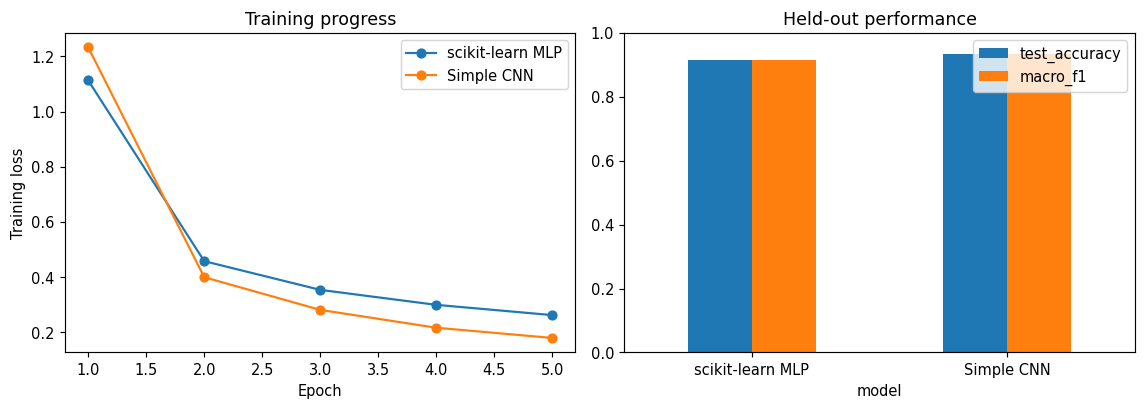

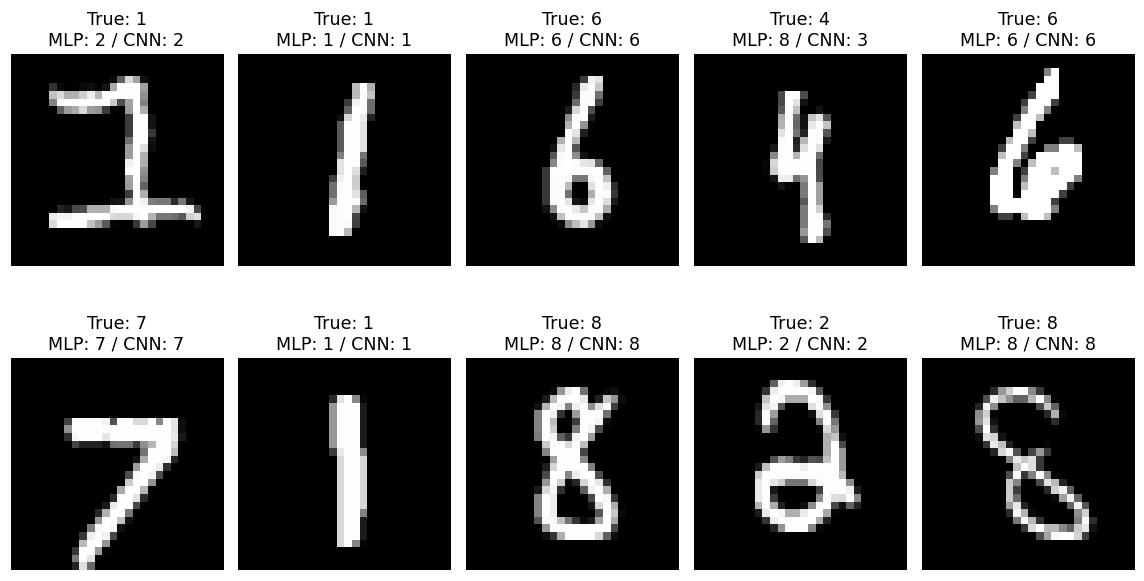

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, MLP_EPOCHS + 1), mlp_loss_history, marker="o", label="scikit-learn MLP")
axes[0].plot(range(1, CNN_EPOCHS + 1), cnn_loss_history, marker="o", label="Simple CNN")
axes[0].set(xlabel="Epoch", ylabel="Training loss", title="Training progress")
axes[0].legend()
comparison_df.plot.bar(
    x="model", y=["test_accuracy", "macro_f1"], ax=axes[1], rot=0,
    ylim=(0, 1),  # Both scores range from zero to one.
)
axes[1].set_title("Held-out performance")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(11, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(test_pixels[index].reshape(IMAGE_SIDE, IMAGE_SIDE), cmap="gray")
    ax.set_title(
        f"True: {test_labels[index]}\n"
        f"MLP: {mlp_predictions[index]} / CNN: {cnn_predictions[index]}"
    )
    ax.axis("off")
plt.tight_layout(h_pad=3.0)
plt.show()  # Compare both predictions for each of the same test images.


Inspect the confusion matrices and the shared prediction examples. Which digits are difficult for each model? Does higher training accuracy also produce higher test accuracy? Relate the observed results to parameter counts and training time.

For further tuning, create a validation split from the training data and reserve the test set for final evaluation. Change settings only after recording the baseline results.